# Lab 8-04：Opik——打點，再把 8-02 的回答交給它評

**目標**：用 Opik 的 `@opik.track` 替 mini RAG 打點、把 judge 分數掛到 trace 上；
再用 Opik 的評估入口，把 8-02 存下來的回答交給三種評分器，看它們意見一不一致。

**你會學到**
- `@opik.track` 打點、把 token 與 judge 分數（feedback score）掛到 trace 上
- 不連伺服器也能看 trace：`opik.record_traces_locally()`
- 用 `opik.evaluate_on_dict_items` 一次跑多個評分器，自寫 judge 也能塞進去
- 有伺服器時，`opik.evaluate()` 會把題庫與每次實驗存起來，網頁上並排比較

**前置**：先跑過 8-01、8-02（本 notebook 讀 `runs/baseline.json`、`runs/prompt_v2.json`）。**這本用相容環境 `.venv-compat` 開**（Opik 最新版仍要求 `openai<3`；安裝方式見本模組 README「準備」）。Opik 帳號選填。Langfuse 與 Opik 怎麼選見 `00_concepts.md` 第 7 節。

**對應投影片**：「評測流程」「評審校準」「選型：評測工具」「選型：可觀測性工具」

![三種評分器對同一批回答打分，意見不同的格子先讀理由](images/scorer_grid.jpg)

*圖：每一列是一種評分器、每一欄是一題，藍＝好、紅＝不好。三列意見一致的題目可以放心；朱紅框起來、意見不同的題目，就是錯誤分析要先讀理由的地方。Step 7 會畫出本機實際跑出來的這張格子圖。*

## Step 1：有沒有 Opik 伺服器？

Opik 預設把 trace 送到 Comet 的雲端。`setup_opik()`（本資料夾的 `opik_setup.py`）在沒有設定時切到本機模式：
網址指到自架的預設位址 `localhost:5173`（那裡沒有伺服器，送出會失敗並被丟棄，**資料不會離開這台機器**），並關掉用量統計與錯誤回報。
一定要在 `import opik` **之前**呼叫。

In [1]:
from opik_setup import setup_opik

LIVE = setup_opik()

沒有 Opik 設定，改用「本機模式」：trace 不上傳，評估指標照常在本機算。

想接上真的 Opik，二選一：
  1. 雲端免費方案：到 https://www.comet.com/signup 註冊，拿 API key
  2. 自架（需要 Docker，約數 GB 磁碟）：照 https://www.comet.com/docs/opik/self-host/local_deployment
     用官方的 docker compose 起服務，介面在 http://localhost:5173

再把設定加到 .env，重開 kernel：
  OPIK_API_KEY=...            # 雲端
  OPIK_WORKSPACE=...          # 雲端
  OPIK_URL_OVERRIDE=http://localhost:5173/api   # 自架只要這行


## Step 2：用 `@opik.track` 打點

Opik 的寫法比 Langfuse 更偏裝飾器：函式被 `@opik.track` 包住就是一個 span，巢狀呼叫自動成為子節點。
token 數用 `opik_context.update_current_span(usage=...)` 補上；judge 分數用 `update_current_trace(feedback_scores=...)` 掛到整個 trace。

In [2]:
import opik
from opik import opik_context

from judge import judge
from mini_rag import MODEL, MiniRAG, load_eval_set, load_faq

rag = MiniRAG(load_faq())


@opik.track(name="retrieve", type="tool")
def retrieve(question: str, top_k: int = 3) -> list[dict]:
    return rag.retrieve(question, top_k)


@opik.track(name="generate", type="llm")
def generate(question: str, hits: list[dict], prompt: str = "v1") -> str:
    gen = rag.generate(question, hits, prompt)
    opik_context.update_current_span(
        model=MODEL, provider="ollama",
        usage={"prompt_tokens": gen["prompt_tokens"], "completion_tokens": gen["completion_tokens"],
               "total_tokens": gen["prompt_tokens"] + gen["completion_tokens"]},
    )
    return gen["answer"]


@opik.track(name="rag-question")
def answer_and_judge(item: dict) -> str:
    opik_context.update_current_trace(tags=["prompt-v1"], metadata={"qid": item["id"]})
    hits = retrieve(item["question"])
    answer = generate(item["question"], hits)
    v = judge(item["question"], item["reference"], answer)
    opik_context.update_current_trace(feedback_scores=[
        {"name": "judge_score", "value": v["score"], "reason": v["reason"]},
        {"name": "passed", "value": float(v["passed"])},
    ])
    return answer

## Step 3：在本機看 trace

`opik.record_traces_locally()` 會把這段期間產生的 trace 收在記憶體裡（有沒有伺服器都可以）。

In [3]:
items = load_eval_set()
with opik.record_traces_locally() as storage:
    for it in [items[0], items[13], items[37]]:
        print(it["id"], answer_and_judge(it)[:50])
    traces = storage.trace_trees

t = traces[0]
print(f"\ntrace：{t.name}，tags={t.tags}，metadata={t.metadata}")
print("feedback scores：", [(s.name, s.value) for s in t.feedback_scores])


def walk(span, depth=0):
    ms = (span.end_time - span.start_time).total_seconds() * 1000
    print("  " * depth + f"└ {span.name}（{span.type}） {ms:.0f} ms  usage={span.usage and span.usage.get('total_tokens')}")
    for child in span.spans:
        walk(child, depth + 1)


for s in t.spans:
    walk(s)

Q01 特休要在人事系統「嵐葉」提前 3 個工作天申請。
Q14 出差的單據最晚要在出差結束後 30 天內上傳報帳系統。
Q38 資料中沒有提到

trace：rag-question，tags=['prompt-v1']，metadata={'qid': 'Q01'}
feedback scores： [('judge_score', 3), ('passed', 0.0)]
└ rag-question（general） 2217 ms  usage=None
  └ retrieve（tool） 20 ms  usage=None
  └ generate（llm） 1367 ms  usage=303


三套寫法放在一起看（同一個 trace，不同名字）：

| 概念 | 最小 JSONL（`00_concepts.md`） | Langfuse（8-03） | Opik |
|---|---|---|---|
| 一題 | `trace_id` | trace | trace |
| 一步 | `step` | observation（`as_type`） | span（`type`：general／tool／llm／guardrail） |
| token | `prompt_tokens` 欄位 | `usage_details` | `usage` |
| judge 分數 | 寫在 output | score（另一支 API） | feedback score |
| 打點方式 | context manager | context manager 或 `@observe` | 主要是 `@opik.track` |

## Step 4：準備要評的回答

不重跑 RAG，直接拿 8-02 存下來的回答：基準版和 prompt v2 各取 6 題（含 3 題「資料裡沒有」的題目）。
LLM 型指標需要「context」，所以再用檢索把每題的前 3 份文件撈出來（只做 embedding，很快）。

In [4]:
import json
from pathlib import Path

import pandas as pd

question_of = {it["id"]: it for it in items}
picked_ids = ["Q01", "Q13", "Q20", "Q30", "Q37", "Q38"]

eval_items = []
for run in ["baseline", "prompt_v2"]:
    rows = {r["id"]: r for r in json.loads(Path(f"runs/{run}.json").read_text(encoding="utf-8"))["rows"]}
    for qid in picked_ids:
        it = question_of[qid]
        eval_items.append({
            "run": run, "qid": qid, "question": it["question"], "reference": it["reference"],
            "answer": rows[qid]["answer"],
            "context": [f"{h['title']}：{h['text']}" for h in rag.retrieve(it["question"], 3)],
        })
pd.DataFrame(eval_items)[["run", "qid", "question", "answer"]].assign(answer=lambda d: d["answer"].str[:40])

,run,qid,question,answer
0,baseline,Q01,特休要提前幾天申請？,特休要在人事系統「嵐葉」提前 3 個工作天申請。
1,baseline,Q13,去高雄出差，住宿一晚最多報多少？,資料中沒有提到
2,baseline,Q20,我 45 歲，多久可以做一次健檢？,資料中沒有提到。
3,baseline,Q30,星期五下午四點可以部署到正式環境嗎？,資料中沒有提到
4,baseline,Q37,公司有提供員工宿舍嗎？,資料中沒有提到
5,baseline,Q38,年終獎金通常發幾個月？,資料中沒有提到
6,prompt_v2,Q01,特休要提前幾天申請？,根據提供的資料[F01]，特休申請需要提前3個工作天。所以，同仁在需要請假時，應
7,prompt_v2,Q13,去高雄出差，住宿一晚最多報多少？,"根據您提供的資料，去高雄出差的住宿費用上限為每晚2,600元。因此，如果同仁在高"
8,prompt_v2,Q20,我 45 歲，多久可以做一次健檢？,根據您提供的資料[F09]，公司規定每2年提供一次員工健康檢查，適用對象為所有員
9,prompt_v2,Q30,星期五下午四點可以部署到正式環境嗎？,根據您提供的資料[F14]，部署凍結時段為每週五15:00到下週一10:00，因


## Step 5：三種評分器

8-01 已經介紹過這三種評分器，這裡直接拿來用：
- `LevenshteinRatio`：字串相似度，不呼叫模型
- `Hallucination`：Opik 內建 LLM 指標，透過 LiteLLM 指到本機 Ollama（模型字串 `ollama_chat/qwen2.5:3b`）
- 本課 judge：`judge.py`，包成 scoring function

In [5]:
from opik.evaluation import metrics

OLLAMA_MODEL = "ollama_chat/" + MODEL
lev = metrics.LevenshteinRatio(track=False)
halluc = metrics.Hallucination(model=OLLAMA_MODEL, track=False)

## Step 6：一次跑完

`opik.evaluate_on_dict_items` 是 Opik 的輕量評估入口：給一串 dict、一個 task、一組指標，它負責呼叫和彙整，不需要伺服器上的資料集。
我們自己的 `judge.py` 也能塞進去，當成 `scoring_functions`。`scoring_threads=1` 是為了不要同時把本機 Ollama 塞爆。

In [6]:
from opik.evaluation.metrics.score_result import ScoreResult


def course_judge(dataset_item: dict, task_outputs: dict) -> ScoreResult:
    v = judge(dataset_item["question"], dataset_item["reference"], task_outputs["output"])
    return ScoreResult(name="course_judge_passed", value=float(v["passed"]), reason=v["reason"])


result = opik.evaluate_on_dict_items(
    items=eval_items,
    task=lambda item: {"output": item["answer"]},  # 回答已經有了，task 只負責交出去
    scoring_metrics=[lev, halluc],
    scoring_functions=[course_judge],
    scoring_key_mapping={"input": "question"},
    scoring_threads=1,
)

rows = []
for tr in result.test_results:
    item = tr.test_case.dataset_item_content
    row = {"run": item["run"], "qid": item["qid"]}
    for s in tr.score_results:
        row[s.name] = None if s.scoring_failed else s.value
    rows.append(row)
scores = pd.DataFrame(rows)
scores

,run,qid,levenshtein_ratio_metric,hallucination_metric,course_judge_passed
0,baseline,Q01,0.857143,0.0,0.0
1,baseline,Q13,0.000000,1.0,0.0
2,baseline,Q20,0.105263,1.0,0.0
3,baseline,Q30,0.000000,1.0,0.0
4,baseline,Q37,0.736842,0.0,1.0
5,baseline,Q38,0.736842,0.8,1.0
6,prompt_v2,Q01,0.188976,0.5,1.0
7,prompt_v2,Q13,0.083832,1.0,1.0
8,prompt_v2,Q20,0.157480,1.0,0.0
9,prompt_v2,Q30,0.156863,0.8,0.0


如果某格是空的（`None`），代表 3B 模型那次沒吐出 Opik 要的格式，指標計算失敗。
內建指標的 prompt 是英文、針對大模型設計的，小模型比較常失敗——這是用現成指標前要先檢查的事。

Hallucination 的 context 是檢索到的前 3 份文件；回答若是「資料中沒有提到」，對它來說可能算「跟 context 無關」，
這種業務規則它不知道，正是自寫 judge 要補的地方。

## Step 7：畫出來——評分器之間意見一致嗎？

把三個分數都換成「這題算不算好」：Levenshtein ≥ 0.5、沒有幻覺（Hallucination = 0）、自寫 judge 通過。

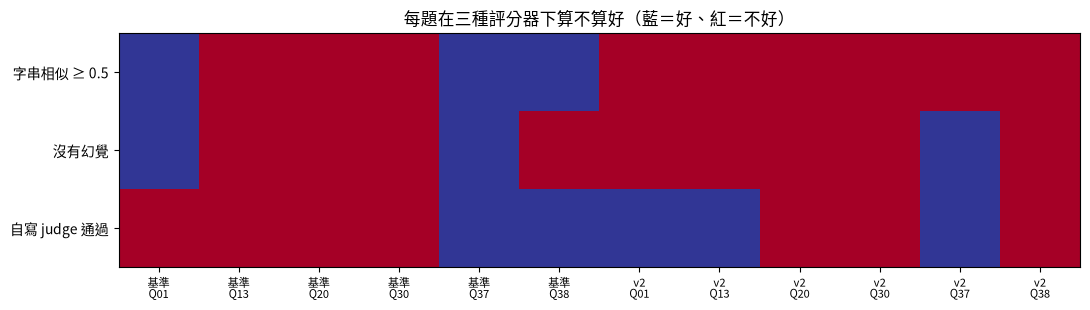

Hallucination 指標與自寫 judge 的一致率：67%
各評分器判「好」的比例： {'字串相似 ≥ 0.5': 0.25, '沒有幻覺': 0.25, '自寫 judge 通過': 0.42}


In [7]:
import matplotlib.pyplot as plt
import numpy as np

from course_utils.viz import setup_cjk

setup_cjk()

good = pd.DataFrame({
    "字串相似 ≥ 0.5": scores["levenshtein_ratio_metric"] >= 0.5,
    "沒有幻覺": scores["hallucination_metric"] == 0,
    "自寫 judge 通過": scores["course_judge_passed"] == 1,
})
labels = [f"{r}\n{i}" for r, i in zip(scores["run"].str.replace("baseline", "基準").str.replace("prompt_v2", "v2"), scores["qid"])]

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(good.T.astype(float).values, cmap="RdYlBu", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(3), good.columns)
ax.set_xticks(range(len(labels)), labels, fontsize=8)
ax.set_title("每題在三種評分器下算不算好（藍＝好、紅＝不好）")
plt.tight_layout()
plt.show()

agree = (good["沒有幻覺"] == good["自寫 judge 通過"]).mean()
print(f"Hallucination 指標與自寫 judge 的一致率：{agree:.0%}")
print("各評分器判「好」的比例：", good.mean().round(2).to_dict())

讀圖的重點：
- 「資料裡沒有」的題目（Q37、Q38），v2 編答案時，Hallucination 和自寫 judge 通常會一起抓到。
- 兩者意見不同的那幾格，就是 8-01 說的「先做錯誤分析」的起點：去讀兩邊的理由，判斷誰錯。
- 字串相似度那一列跟另外兩列常常對不起來，再次說明它不適合判對錯。

現成指標的價值是**省下寫 prompt 的時間、而且大家用同一把尺**；代價是它不知道你的業務規則（例如「資料沒有就要說沒有」），
也沒有被你的人工標註校準過。實務上兩種一起用：現成指標當廣度、自寫 judge 管你最在意的規則。

## Step 8：在伺服器上跑正式實驗（需要 Opik 伺服器）

`evaluate_on_dict_items` 是輕量版；正式的 `opik.evaluate()` 會把題庫存成伺服器上的 Dataset、每次跑留下一個 Experiment，
可以在網頁上並排比較基準版和候選版——就是 8-02 對比表的平台版。

In [8]:
if LIVE:
    client = opik.Opik()
    dataset = client.get_or_create_dataset(name="m8-faq-eval")
    dataset.insert([{"question": it["question"], "reference": it["reference"]} for it in items[:10]])
    exp = opik.evaluate(
        dataset=dataset,
        task=lambda item: {"output": generate(item["question"], retrieve(item["question"]))},
        scoring_metrics=[lev],
        experiment_name="baseline-v1-top3",
        task_threads=1,
    )
    print("實驗已建立，到 Opik 網頁的 Experiments 頁查看。")
else:
    print("本機模式：略過 opik.evaluate()（它需要伺服器存 Dataset 與 Experiment）。")

本機模式：略過 opik.evaluate()（它需要伺服器存 Dataset 與 Experiment）。


## Step 9：什麼時候選 Opik

一句話：**想要開源、可自架，而且評估指標要現成、能直接在 notebook 算分，就選 Opik**（Apache 2.0 授權）。

| 需求 | 建議 |
|---|---|
| trace 和 prompt 管理為主、要自架 | Langfuse（MIT） |
| 評估指標多、要在 notebook 或 CI 直接算分 | Opik（Apache 2.0） |
| 已經全用 LangChain／LangGraph、要現成的團隊協作與標註介面 | LangSmith（閉源 SaaS） |

不管哪個平台，8-01 的原則都不變：judge 先拿人工標註校準，再拿來擋回歸。

## 試試看

1. 在 `scoring_metrics` 加上 `metrics.AnswerRelevance(model=OLLAMA_MODEL, track=False)`，看它對 v2「熱情但編造」的回答給幾分。它抓得到問題嗎？
2. 把 Hallucination 的 context 從「檢索到的文件」改成「參考答案」，重跑 Step 6。它跟自寫 judge 的一致率有變嗎？為什麼？
3. 用 `metrics.GEval` 寫一個「資料沒有就要說沒有」的自訂指標（task_introduction 與 evaluation_criteria 用中文寫），跟自寫 judge 比較。

## 小結

- Opik 用 `@opik.track` 打點，trace／span／feedback score 對應到 Langfuse 的 trace／observation／score；`record_traces_locally` 不連伺服器也能看。
- 內建指標分兩種：規則型便宜但不懂語意，LLM 型可以透過 LiteLLM 指到本機 Ollama 在本地算分，但小模型偶爾吐不出格式。
- 現成指標是廣度，自寫並校準過的 judge 是深度。下一本 8-05 把 8-01～8-03 量到的數字寫成履歷，再用 judge 練面試。